# FCN Risk Simulator

**How does a worst-of Fixed Coupon Note (FCN) behave in different markets, and where does its risk come from?**

A Fixed Coupon Note is a structured product widely sold to wealth-management clients. The investor earns a fixed monthly coupon, but in exchange takes on the risk of receiving shares in the worst-performing stock if markets fall sharply. In option terms, the investor is effectively **selling a put option** on the worst of several stocks.

This notebook:
1. estimates volatility and correlation for the underlying stocks from public market data,
2. simulates thousands of possible price paths with a Monte Carlo model,
3. prices the note to find a realistic coupon,
4. compares outcomes in bull, sideways and sell-off markets against simply holding the stocks,
5. tests how strike, volatility and correlation change the risk, and
6. back-tests the same note on real historical prices.

*For educational purposes only. Uses public market data only; not investment advice.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)

## 1. Settings

The product terms below describe a typical, simplified worst-of FCN. Change them to test other structures.

In [3]:
# ---- Underlying stocks ----
TICKERS = ["TSM", "NVDA"]      # TSMC (ADR) and NVIDIA: popular FCN underlyings in Asian private banking
LOOKBACK_YEARS = 3              # history used to estimate volatility and correlation
BACKTEST_YEARS = 10             # history used for the historical back-test

# ---- Product terms ----
TERMS = dict(
    tenor_months=12,   # maximum life of the note
    ko_level=1.00,     # knock-out: if ALL stocks are >= 100% of their initial price on a monthly
                       # observation date, the note ends early and the investor gets 100% back
    strike=0.85,       # at maturity, if the worst stock is below 85% of its initial price, the investor
                       # receives that stock at the strike price (physical delivery) instead of cash
    coupon_pa=None,    # annual coupon, paid monthly until knock-out or maturity.
                       # None = set automatically in Section 4 (fair coupon minus the issuer's margin)
)
ISSUER_MARGIN = 0.02   # assumed annual margin kept by the issuing bank

# ---- Model settings ----
RISK_FREE = 0.04       # risk-free rate, used to price the note
DAYS_PER_MONTH = 21
DAYS_PER_YEAR = 252
N_PATHS = 20_000
SEED = 42

## 2. What the investor gets at maturity

If the note is **never knocked out**, the investor collects all 12 monthly coupons, and the capital returned depends on the worst stock's final level:

- worst stock **at or above the strike** → 100% of capital back;
- worst stock **below the strike** → shares worth *final level ÷ strike* (e.g. a stock at 60% with an 85% strike returns 0.60 / 0.85 ≈ 71% of capital). Below the strike, the investor loses about 1.2× as fast as the stock itself (1 ÷ 0.85), because the shares are bought at the strike price.

The chart compares this with holding the stock directly. The FCN gives up all upside above the coupon in exchange for a cushion against moderate falls.

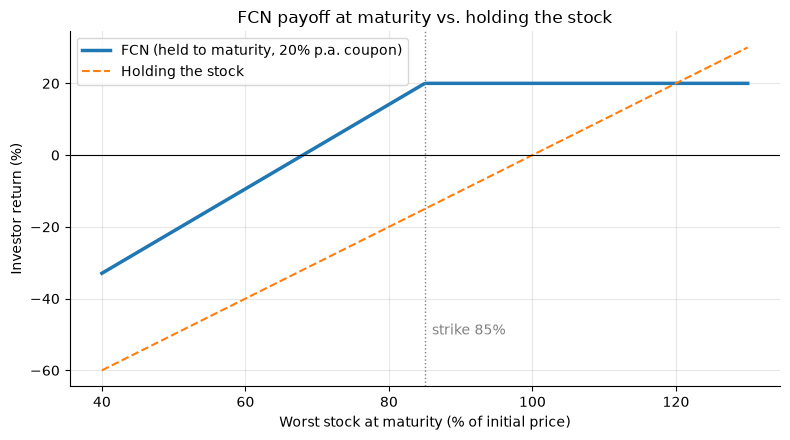

In [4]:
def payoff_at_maturity(worst_final, strike, coupon_pa, tenor_months=12):
    coupons = coupon_pa * tenor_months / 12
    capital = np.minimum(1.0, worst_final / strike)
    return coupons + capital - 1

x = np.linspace(0.40, 1.30, 300)
illustrative_coupon = 0.20   # for this picture only; the real coupon is set in Section 5
plt.plot(x * 100, payoff_at_maturity(x, TERMS["strike"], illustrative_coupon) * 100,
         lw=2.5, label=f"FCN (held to maturity, {illustrative_coupon:.0%} p.a. coupon)")
plt.plot(x * 100, (x - 1) * 100, "--", label="Holding the stock")
plt.axvline(TERMS["strike"] * 100, color="grey", lw=1, ls=":")
plt.text(TERMS["strike"] * 100 + 1, -50, f"strike {TERMS['strike']:.0%}", color="grey")
plt.axhline(0, color="black", lw=0.8)
plt.xlabel("Worst stock at maturity (% of initial price)")
plt.ylabel("Investor return (%)")
plt.title("FCN payoff at maturity vs. holding the stock")
plt.legend(); plt.tight_layout()
plt.savefig(FIG_DIR / "01_payoff.png", dpi=150); plt.show()

## 3. Market data

Daily adjusted closing prices are downloaded from Yahoo Finance (and cached locally). Volatility and correlation are estimated from daily log returns over the last few years.

Prices from Yahoo Finance: 2512 trading days, 2016-10-21 to 2026-10-20


,Annualised volatility,Annualised return,Max drawdown
Ticker,,,
TSM,40.0%,52.9%,-36.8%
NVDA,46.6%,55.6%,-36.9%


Correlation between TSM and NVDA: 0.68


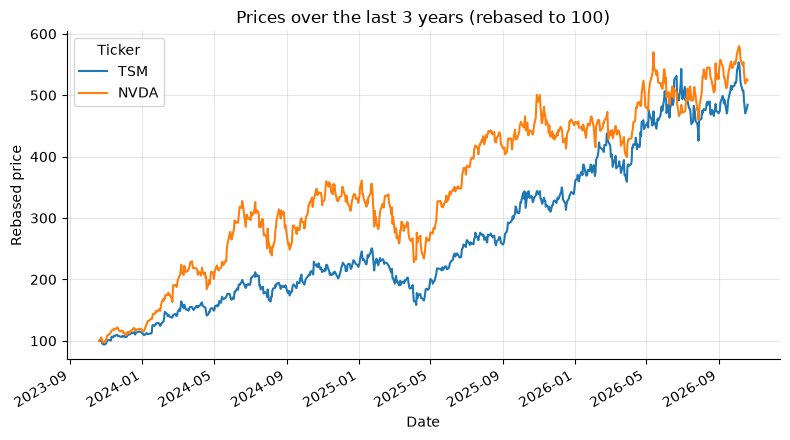

In [5]:
def load_prices(tickers, years, cache_file="prices.csv"):
    # Download adjusted daily closes; fall back to the local cache if the download fails.
    cache = DATA_DIR / cache_file
    end = pd.Timestamp.today().normalize()
    start = end - pd.DateOffset(years=years)
    try:
        import yfinance as yf, logging
        logging.getLogger("yfinance").setLevel(logging.CRITICAL)
        px = yf.download(tickers, start=start, end=end, auto_adjust=True, progress=False)["Close"]
        px = px[tickers].dropna()
        if len(px) < 250:
            raise ValueError("download returned too little data")
        px.to_csv(cache)
        source = "Yahoo Finance"
    except Exception as err:
        if not cache.exists():
            raise RuntimeError(f"Could not download prices ({err}) and no cache found at {cache}")
        px = pd.read_csv(cache, index_col=0, parse_dates=True)[tickers]
        source = f"local cache ({cache})"
    print(f"Prices from {source}: {len(px)} trading days, {px.index[0].date()} to {px.index[-1].date()}")
    return px

prices_all = load_prices(TICKERS, BACKTEST_YEARS)
prices = prices_all[prices_all.index >= prices_all.index[-1] - pd.DateOffset(years=LOOKBACK_YEARS)]
log_ret = np.log(prices).diff().dropna()

vol = log_ret.std() * np.sqrt(DAYS_PER_YEAR)              # annualised volatility
corr = log_ret.corr()                                     # correlation of daily returns
drawdown = (prices / prices.cummax() - 1).min()           # worst peak-to-trough fall

stats = pd.DataFrame({"Annualised volatility": vol,
                      "Annualised return": log_ret.mean() * DAYS_PER_YEAR,
                      "Max drawdown": drawdown})
display(stats.style.format("{:.1%}"))
print(f"Correlation between {TICKERS[0]} and {TICKERS[1]}: {corr.iloc[0, 1]:.2f}")

(prices / prices.iloc[0] * 100).plot(title=f"Prices over the last {LOOKBACK_YEARS} years (rebased to 100)")
plt.ylabel("Rebased price"); plt.tight_layout()
plt.savefig(FIG_DIR / "02_prices.png", dpi=150); plt.show()

## 4. Monte Carlo engine and FCN payoff

**Price paths.** Each stock follows a geometric Brownian motion (GBM). Daily shocks are drawn from a normal distribution and linked across the stocks with a **Cholesky decomposition** of the correlation matrix, so the simulated stocks move together as much as they did historically.

**Payoff.** On each monthly observation date the note checks for knock-out using the **worst** stock. If it never knocks out, the strike test is applied at maturity.

In [6]:
rng = np.random.default_rng(SEED)
N_STEPS = TERMS["tenor_months"] * DAYS_PER_MONTH
RAW_SHOCKS = rng.standard_normal((N_PATHS, N_STEPS, len(TICKERS)))   # reused everywhere (common random numbers)

def correlate(raw, corr_matrix):
    # Turn independent normal shocks into correlated ones via the Cholesky factor.
    L = np.linalg.cholesky(np.asarray(corr_matrix))
    return raw @ L.T

def simulate_paths(z, mu, sigma, dt=1 / DAYS_PER_YEAR):
    # GBM price paths relative to the start (all paths start at 1.0).
    # Output shape: (paths, days + 1, stocks).
    mu, sigma = np.asarray(mu, float), np.asarray(sigma, float)
    steps = (mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * z
    log_paths = np.concatenate([np.zeros((z.shape[0], 1, z.shape[2])), np.cumsum(steps, axis=1)], axis=1)
    return np.exp(log_paths)

def fcn_outcomes(worst, terms):
    # worst: (paths, days + 1) performance of the worst stock on each day.
    m = terms["tenor_months"]
    monthly_coupon = (terms["coupon_pa"] or 0.0) / 12
    obs = worst[:, np.arange(1, m + 1) * DAYS_PER_MONTH]         # monthly observation dates
    ko_hit = obs >= terms["ko_level"]
    knocked_out = ko_hit.any(axis=1)
    months = np.where(knocked_out, ko_hit.argmax(axis=1) + 1, m)  # coupons paid until knock-out
    final = obs[:, -1]
    capital = np.where(knocked_out, 1.0, np.minimum(1.0, final / terms["strike"]))
    return pd.DataFrame({
        "knocked_out": knocked_out,
        "months": months,
        "delivered": ~knocked_out & (final < terms["strike"]),
        "capital": capital,
        "total_return": monthly_coupon * months + capital - 1,
    })

### Sanity checks
Simple paths with known answers, to make sure the payoff logic is right.

In [7]:
test_terms = {**TERMS, "coupon_pa": 0.12}
flat = np.ones((1, N_STEPS + 1))                                  # nothing moves
r = fcn_outcomes(flat, test_terms).iloc[0]
assert r.knocked_out and r.months == 1 and np.isclose(r.total_return, 0.01)

stuck = np.full((1, N_STEPS + 1), 0.90); stuck[0, 0] = 1.0       # stays at 90%: no KO, no delivery
r = fcn_outcomes(stuck, test_terms).iloc[0]
assert not r.knocked_out and not r.delivered and np.isclose(r.total_return, 0.12)

crash = np.linspace(1.0, 0.60, N_STEPS + 1)[None, :]              # slides to 60%: delivery
r = fcn_outcomes(crash, test_terms).iloc[0]
assert r.delivered and np.isclose(r.capital, 0.60 / 0.85)
print("All sanity checks passed ✓")

All sanity checks passed ✓


## 5. What coupon would a bank offer?

Banks price these notes in a **risk-neutral** world: every stock is assumed to grow at the risk-free rate, and cash flows are discounted at that rate. The fair coupon is the one that makes the note worth exactly 100% of its price:

$$\text{PV(capital returned)} + c \times \text{PV(monthly coupon stream)} = 1 \;\Rightarrow\; c = \frac{1 - \text{PV(capital)}}{\text{PV(coupon stream)}}$$

The issuer keeps a margin, so the coupon offered to clients is the fair coupon minus that margin. This coupon is then used in every scenario below.

In [8]:
def fair_coupon(worst, terms, r=RISK_FREE):
    m = terms["tenor_months"]
    out = fcn_outcomes(worst, {**terms, "coupon_pa": 0.0})
    life = out["months"].to_numpy()
    pv_capital = (out["capital"].to_numpy() * np.exp(-r * life / 12)).mean()
    k = np.arange(1, m + 1)
    paid = k[None, :] <= life[:, None]                       # which monthly coupons get paid
    pv_coupon_stream = (paid * np.exp(-r * k / 12)).sum(axis=1).mean()
    return (1 - pv_capital) / pv_coupon_stream * 12          # annualised

def worst_of(paths):
    return paths.min(axis=2)

Z = correlate(RAW_SHOCKS, corr)
rn_paths = simulate_paths(Z, [RISK_FREE] * len(TICKERS), vol.values)
FAIR = fair_coupon(worst_of(rn_paths), TERMS)
if TERMS["coupon_pa"] is None:
    TERMS["coupon_pa"] = np.floor((FAIR - ISSUER_MARGIN) * 200) / 200   # round down to 0.5%
print(f"Fair coupon: {FAIR:.1%} p.a.  →  coupon offered to clients: {TERMS['coupon_pa']:.1%} p.a. "
      f"({TERMS['coupon_pa'] / 12:.2%} per month)")

Fair coupon: 22.1% p.a.  →  coupon offered to clients: 20.0% p.a. (1.67% per month)


## 6. Scenario analysis: bull, sideways and sell-off markets

The same note is run through three market scenarios. Each uses the historical correlation; the scenarios differ in the expected annual return (drift) and the level of volatility.

As a benchmark, the investor could instead **hold an equal-weight basket of the two stocks for 12 months**.

*Note: FCN returns are over the note's actual life. If it knocks out early, the investor gets the money back sooner and has to reinvest it (reinvestment risk), so the FCN and basket returns cover different holding periods.*

In [9]:
SCENARIOS = {
    "Bull":     dict(mu=0.20,  vol_mult=1.0),
    "Sideways": dict(mu=0.00,  vol_mult=0.8),
    "Sell-off": dict(mu=-0.20, vol_mult=1.3),
}

def summarise(out, basket):
    r = out["total_return"]
    return pd.Series({
        "Knock-out probability": out["knocked_out"].mean(),
        "Average life (months)": out["months"].mean(),
        "Delivery probability": out["delivered"].mean(),
        "Probability of loss": (r < 0).mean(),
        "FCN expected return": r.mean(),
        "FCN worst 5% outcome": r.quantile(0.05),
        "Basket expected return": basket.mean(),
        "Basket worst 5% outcome": np.quantile(basket, 0.05),
    })

results, sims = {}, {}
for name, s in SCENARIOS.items():
    paths = simulate_paths(Z, [s["mu"]] * len(TICKERS), vol.values * s["vol_mult"])
    out = fcn_outcomes(worst_of(paths), TERMS)
    basket = paths[:, -1, :].mean(axis=1) - 1            # equal-weight basket held for 12 months
    results[name], sims[name] = summarise(out, basket), (out, basket)

scenario_table = pd.DataFrame(results)
fmt = {row: ("{:.1f}" if "months" in row else "{:.1%}") for row in scenario_table.index}
display(scenario_table.apply(lambda col: [fmt[i].format(v) for i, v in col.items()]))
scenario_table.to_csv("scenario_results.csv")

,Bull,Sideways,Sell-off
Knock-out probability,79.7%,68.9%,56.5%
Average life (months),4.6,5.6,6.6
Delivery probability,17.7%,26.9%,42.0%
Probability of loss,11.3%,16.6%,37.0%
FCN expected return,2.8%,2.4%,-8.5%
FCN worst 5% outcome,-17.2%,-19.5%,-50.0%
Basket expected return,22.2%,0.0%,-18.1%
Basket worst 5% outcome,-40.9%,-43.4%,-69.0%


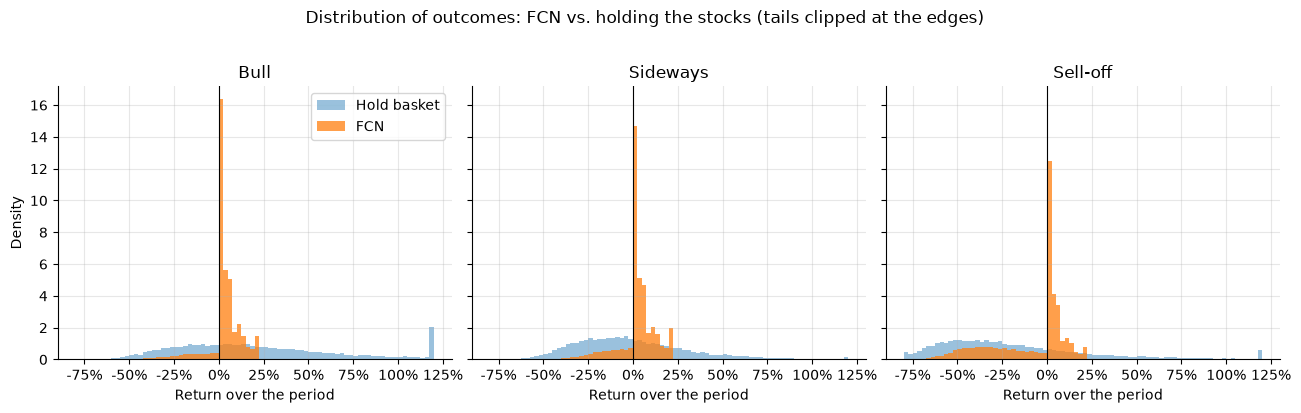

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
lo_, hi_ = -0.8, 1.2
bins = np.linspace(lo_, hi_, 81)
for ax, (name, (out, basket)) in zip(axes, sims.items()):
    ax.hist(np.clip(basket, lo_, hi_), bins=bins, alpha=0.45, density=True, label="Hold basket")
    ax.hist(np.clip(out["total_return"], lo_, hi_), bins=bins, alpha=0.75, density=True, label="FCN")
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(name); ax.set_xlabel("Return over the period")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_ylabel("Density"); axes[0].legend()
fig.suptitle("Distribution of outcomes: FCN vs. holding the stocks (tails clipped at the edges)", y=1.02)
plt.tight_layout(); plt.savefig(FIG_DIR / "03_scenarios.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Sensitivity: what drives the coupon and the risk?

Using common random numbers (the same shocks every time), so the curves are smooth:
- **Strike** – how much cushion the investor has before taking delivery;
- **Volatility** – how much the stocks move;
- **Correlation** – how closely the two stocks move together. Lower correlation makes the *worst* of the two more likely to fall a lot.

Sensitivity direction checks passed ✓


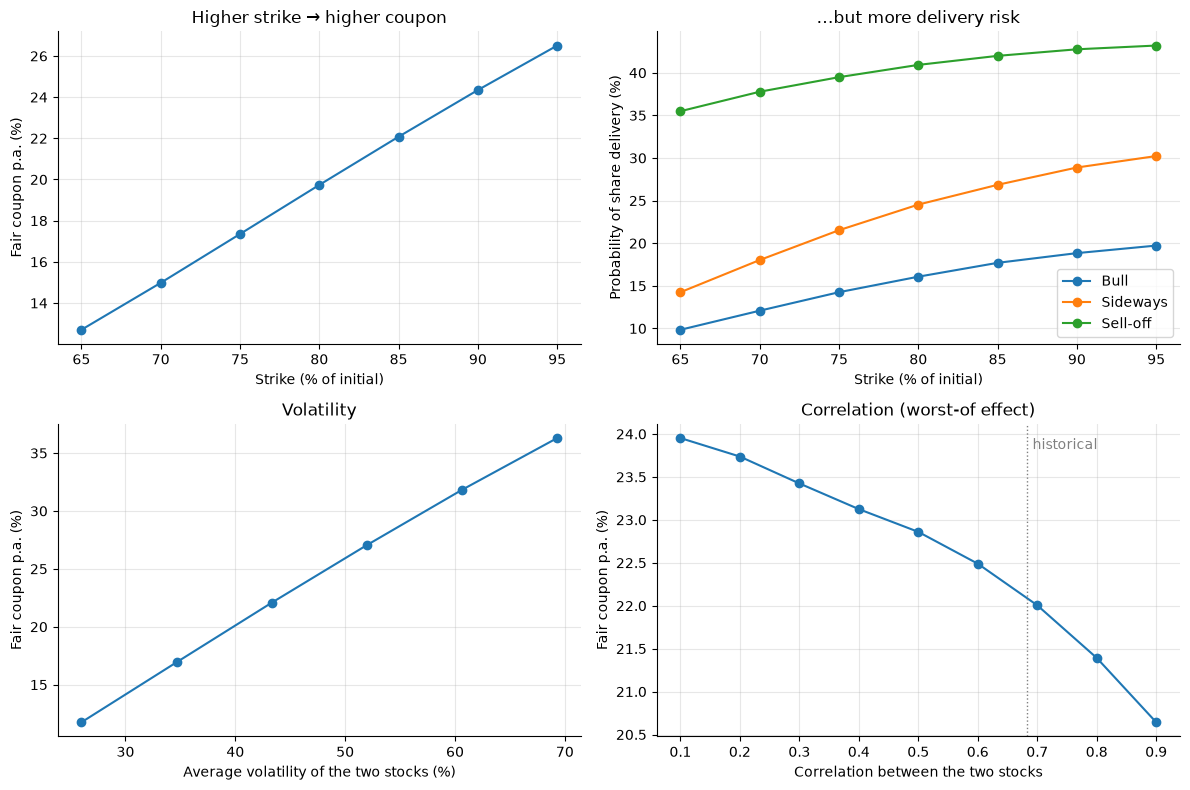

,fair_coupon,delivery_Bull,delivery_Sideways,delivery_Sell-off
strike,,,,
65%,12.7%,9.8%,14.2%,35.5%
70%,15.0%,12.1%,18.0%,37.8%
75%,17.4%,14.3%,21.5%,39.5%
80%,19.7%,16.1%,24.5%,40.9%
85%,22.1%,17.7%,26.9%,42.0%
90%,24.3%,18.8%,28.9%,42.8%
95%,26.5%,19.7%,30.2%,43.2%


In [11]:
def risk_neutral_worst(vol_mult=1.0, rho=None):
    c = corr.values.copy()
    if rho is not None:
        c = np.array([[1.0, rho], [rho, 1.0]])
    z = correlate(RAW_SHOCKS, c)
    return worst_of(simulate_paths(z, [RISK_FREE] * len(TICKERS), vol.values * vol_mult))

def scenario_worst(name):
    s = SCENARIOS[name]
    return worst_of(simulate_paths(Z, [s["mu"]] * len(TICKERS), vol.values * s["vol_mult"]))

base_rn = risk_neutral_worst()
scen_worst = {name: scenario_worst(name) for name in SCENARIOS}
strikes = np.round(np.arange(0.65, 0.96, 0.05), 2)
strike_rows = []
for k in strikes:
    t = {**TERMS, "strike": k}
    row = {"strike": k, "fair_coupon": fair_coupon(base_rn, t)}
    row.update({f"delivery_{n}": fcn_outcomes(w, t)["delivered"].mean() for n, w in scen_worst.items()})
    strike_rows.append(row)
by_strike = pd.DataFrame(strike_rows)

vol_mults = np.round(np.arange(0.6, 1.61, 0.2), 2)
by_vol = pd.DataFrame({"vol_mult": vol_mults,
                       "fair_coupon": [fair_coupon(risk_neutral_worst(vm), TERMS) for vm in vol_mults]})
rhos = np.round(np.arange(0.1, 0.91, 0.1), 2)
by_rho = pd.DataFrame({"rho": rhos,
                       "fair_coupon": [fair_coupon(risk_neutral_worst(rho=p), TERMS) for p in rhos]})

# Direction checks: each driver should move the coupon the way option theory predicts
assert by_strike.fair_coupon.is_monotonic_increasing, "higher strike should mean higher coupon"
assert by_vol.fair_coupon.is_monotonic_increasing, "higher volatility should mean higher coupon"
assert by_rho.fair_coupon.is_monotonic_decreasing, "higher correlation should mean lower coupon"
print("Sensitivity direction checks passed ✓")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
ax = axes[0, 0]
ax.plot(by_strike.strike * 100, by_strike.fair_coupon * 100, "o-")
ax.set_xlabel("Strike (% of initial)"); ax.set_ylabel("Fair coupon p.a. (%)"); ax.set_title("Higher strike → higher coupon")
ax = axes[0, 1]
for n in SCENARIOS:
    ax.plot(by_strike.strike * 100, by_strike[f"delivery_{n}"] * 100, "o-", label=n)
ax.set_xlabel("Strike (% of initial)"); ax.set_ylabel("Probability of share delivery (%)")
ax.set_title("…but more delivery risk"); ax.legend()
ax = axes[1, 0]
ax.plot(by_vol.vol_mult * vol.mean() * 100, by_vol.fair_coupon * 100, "o-")
ax.set_xlabel("Average volatility of the two stocks (%)"); ax.set_ylabel("Fair coupon p.a. (%)"); ax.set_title("Volatility")
ax = axes[1, 1]
ax.plot(by_rho.rho, by_rho.fair_coupon * 100, "o-")
ax.axvline(corr.iloc[0, 1], color="grey", ls=":", lw=1)
ax.text(corr.iloc[0, 1] + 0.01, by_rho.fair_coupon.max() * 100, "historical", color="grey", va="top")
ax.set_xlabel("Correlation between the two stocks"); ax.set_ylabel("Fair coupon p.a. (%)"); ax.set_title("Correlation (worst-of effect)")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_sensitivity.png", dpi=150); plt.show()
display(by_strike.set_index("strike").rename(index=lambda v: f"{v:.0%}").style.format("{:.1%}"))

## 8. Historical back-test

What would have happened if an investor had bought this note (with today's terms) every week over the last decade? Each start date uses the **actual** price path of the following 12 months.

*Caveats: the windows overlap, so they are not independent; and in reality the coupon offered at each start date would have depended on volatility at that time.*

,Notes simulated,Knock-out rate,Delivery rate,Average return,Worst outcome
Historical back-test,452,92.0%,5.1%,3.9%,-22.7%


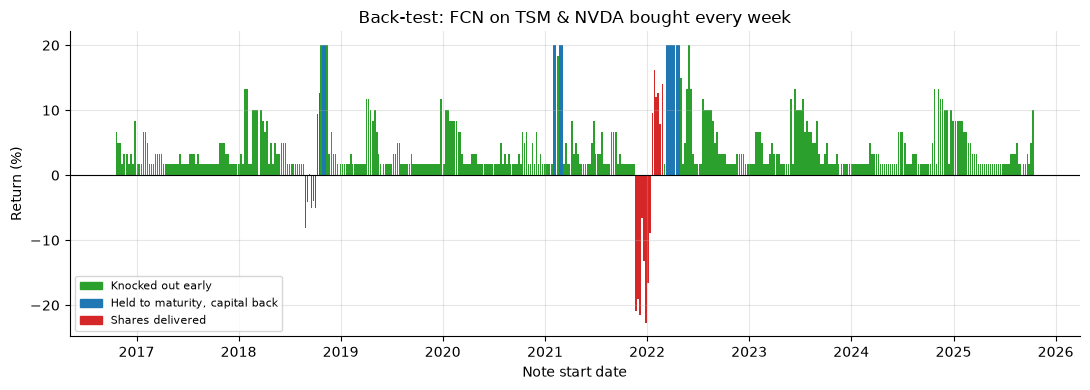

In [12]:
px_arr = prices_all.to_numpy()
starts = np.arange(0, len(px_arr) - N_STEPS, 5)                       # one note per week
windows = np.stack([px_arr[s:s + N_STEPS + 1] / px_arr[s] for s in starts])
bt = fcn_outcomes(worst_of(windows), TERMS)
bt.index = prices_all.index[starts]

bt_summary = pd.Series({
    "Notes simulated": len(bt),
    "Knock-out rate": bt["knocked_out"].mean(),
    "Delivery rate": bt["delivered"].mean(),
    "Average return": bt["total_return"].mean(),
    "Worst outcome": bt["total_return"].min(),
})
display(bt_summary.to_frame("Historical back-test").T.style.format(
    {"Notes simulated": "{:.0f}", **{c: "{:.1%}" for c in bt_summary.index[1:]}}))

colors = np.where(bt["delivered"], "tab:red", np.where(bt["knocked_out"], "tab:green", "tab:blue"))
plt.figure(figsize=(11, 4))
plt.bar(bt.index, bt["total_return"] * 100, width=6, color=colors)
plt.axhline(0, color="black", lw=0.8)
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color="tab:green", label="Knocked out early"),
                    Patch(color="tab:blue", label="Held to maturity, capital back"),
                    Patch(color="tab:red", label="Shares delivered")], fontsize=8)
plt.ylabel("Return (%)"); plt.xlabel("Note start date")
plt.title(f"Back-test: FCN on {' & '.join(TICKERS)} bought every week")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_backtest.png", dpi=150); plt.show()

## 9. Key findings

In [13]:
s, b = scenario_table, by_strike
lo, hi = b.iloc[0], b.iloc[-1]
f = lambda row, col: s.loc[row, col]
print(f"1. Pricing: with ~{vol.mean():.0%} average volatility and {corr.iloc[0,1]:.2f} correlation, the fair coupon is "
      f"{FAIR:.1%} p.a.; after a {ISSUER_MARGIN:.0%} margin, clients would be offered about {TERMS['coupon_pa']:.1%} p.a.")
print(f"2. Versus holding the stocks: the FCN returns {f('FCN expected return','Sideways'):.1%} vs {f('Basket expected return','Sideways'):.1%} "
      f"in a sideways market and {f('FCN expected return','Sell-off'):.1%} vs {f('Basket expected return','Sell-off'):.1%} in a sell-off, "
      f"but only {f('FCN expected return','Bull'):.1%} vs {f('Basket expected return','Bull'):.1%} in a bull market, because the upside is capped at the coupon.")
print(f"3. Early knock-out: in a bull market the note ends early {f('Knock-out probability','Bull'):.0%} of the time "
      f"(average life {f('Average life (months)','Bull'):.1f} months), so the high coupon is earned only briefly and the money must be reinvested.")
print(f"4. Tail risk: in a sell-off, {f('Delivery probability','Sell-off'):.0%} of notes end in share delivery and the worst 5% lose "
      f"{-f('FCN worst 5% outcome','Sell-off'):.0%}. The coupon cushions small falls, not large ones.")
print(f"5. Strike trade-off: lowering the strike from {hi.strike:.0%} to {lo.strike:.0%} cuts the fair coupon from {hi.fair_coupon:.1%} to "
      f"{lo.fair_coupon:.1%}, and sideways-market delivery probability from {hi.delivery_Sideways:.0%} to {lo.delivery_Sideways:.0%}.")
print(f"6. Correlation: the fair coupon rises from {by_rho.fair_coupon.iloc[-1]:.1%} at 0.9 correlation to {by_rho.fair_coupon.iloc[0]:.1%} at 0.1, "
      f"because the investor is exposed to the WORST of the two stocks.")
print(f"7. Back-test: of {len(bt)} weekly notes, {bt['knocked_out'].mean():.0%} knocked out early and {bt['delivered'].mean():.0%} ended in "
      f"delivery; the worst note returned {bt['total_return'].min():.0%}.")

1. Pricing: with ~43% average volatility and 0.68 correlation, the fair coupon is 22.1% p.a.; after a 2% margin, clients would be offered about 20.0% p.a.
2. Versus holding the stocks: the FCN returns 2.4% vs 0.0% in a sideways market and -8.5% vs -18.1% in a sell-off, but only 2.8% vs 22.2% in a bull market, because the upside is capped at the coupon.
3. Early knock-out: in a bull market the note ends early 80% of the time (average life 4.6 months), so the high coupon is earned only briefly and the money must be reinvested.
4. Tail risk: in a sell-off, 42% of notes end in share delivery and the worst 5% lose 50%. The coupon cushions small falls, not large ones.
5. Strike trade-off: lowering the strike from 95% to 65% cuts the fair coupon from 26.5% to 12.7%, and sideways-market delivery probability from 30% to 14%.
6. Correlation: the fair coupon rises from 20.6% at 0.9 correlation to 24.0% at 0.1, because the investor is exposed to the WORST of the two stocks.
7. Back-test: of 452 we

## 10. Limitations and next steps

**Limitations**
- GBM assumes constant volatility and normally distributed returns; real markets have volatility clusters and sudden jumps, so the model likely **understates** crash risk.
- Dividends, funding costs and the issuer's credit risk are ignored.
- The scenario drifts and volatility multipliers are illustrative assumptions, not forecasts.
- Physical delivery is valued at the market price at maturity; in practice the investor then holds the shares and may recover or lose more.

**Roadmap**
- Replace constant volatility with a **GARCH(1,1)** forecast.
- Train a **neural network** (TensorFlow) as a fast surrogate model that estimates the fair coupon and delivery risk directly from product terms.
- Add more underlyings (e.g. Hong Kong stocks) and other features such as a knock-in barrier or step-down knock-out.